## Backtest

In [1]:
import warnings; warnings.filterwarnings("ignore", category=UserWarning)
from pathlib import Path
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from features import FULL_DB, FEATURES, FUNDAMENTAL_FEATURES, load_calendar
from course_data import make_pipeline
import backtester as B

In [2]:
panel = pd.read_parquet("outputs/panel_full.parquet")
feats = FEATURES + FUNDAMENTAL_FEATURES

dev = panel.loc[panel.eligible & panel.date.between("2010-01-01", "2015-12-31")
                & panel.target.notna() & panel.label_end.le("2016-03-31")].copy()
dev["target_rank"] = dev.groupby("date").target.rank(pct=True) - 0.5
model = make_pipeline(HistGradientBoostingRegressor(max_iter=100, max_leaf_nodes=15, min_samples_leaf=200,
                                                    l2_regularization=10, early_stopping=False, random_state=42),
                      numeric_features=feats, include_sector=False).fit(dev[feats], dev.target_rank)


In [3]:
with duckdb.connect(str(FULL_DB), read_only=True) as con:
    u = con.execute("SELECT symbol, exchange FROM universe").fetchdf()
common = set(u.symbol[[B.is_common_stock(s, e) for s, e in zip(u.symbol, u.exchange)]])

test = panel.loc[panel.date.between("2016-03-31", "2026-09-30") & panel.eligible
                 & panel.is_universe_member.astype(bool) & panel.symbol.isin(common)].copy()
test["score"] = model.predict(test[feats])            # target/label_end are never used here
scores = test[["date", "symbol", "score", "close"]]
scores.groupby("date").size().describe()

count     126.000000
mean     1962.238095
std        17.400887
min      1916.000000
25%      1950.250000
50%      1960.500000
75%      1978.000000
max      1992.000000
dtype: float64

In [4]:
quotes = B.load_prices(FULL_DB, "2016-03-31", "2026-09-30", scores.symbol.unique(), load_calendar(FULL_DB))
strategy = B.TopNStrategy(scores, top_n=30, cohort_fraction=1/3, min_price=5, min_order=1_000)
history, fills, open_lots, log = B.run_backtest(quotes, strategy, B.Portfolio(1_000_000, fee_bps=10))
history = history.loc["2016-04-01":]
bench = B.benchmark_nav(FULL_DB, "2016-04-01", "2026-09-30")
log.event.value_counts()

event
exit_waiting          43
late_exit              1
skipped_no_quote       1
suspicious_jump_x3     1
Name: count, dtype: int64

In [5]:
assert np.allclose(history.nav, history.cash + history.holdings)               
assert abs(1_000_000 + fills.cash_change.sum() - history.cash.iloc[-1]) < 1e-4 
assert (fills.groupby("date").cash_change.sum().cumsum() + 1_000_000 >= -1e-6).all() 
buys = fills[fills.side == "buy"]
signal_days = set(scores.date.unique())                  # build once (126 dates)
assert not buys.date.isin(signal_days).any()      
display(fills[fills.symbol == fills.symbol.iloc[0]])
print(f"average cash weight: {(history.cash / history.nav).mean():.1%}")

,date,side,lot_id,symbol,units,price,notional,fee,cash_change,pnl
0,2016-04-01,buy,1,SPB,152.013299,73.02,11100.011100,11.100011,-11111.111111,NaN
90,2016-06-30,sell,1,SPB,152.013299,72.97,11092.410435,11.092410,11081.318025,-29.793086


average cash weight: 17.9%


In [6]:
perf = pd.DataFrame({"Strategy": B.performance(history.nav), "^SP500TR": B.performance(bench)})

shown = perf.astype(object)
shown.loc["final_value"] = perf.loc["final_value"].map("${:,.0f}".format)
for row in ["total_return", "CAGR", "max_drawdown", "annual_vol"]:
    shown.loc[row] = perf.loc[row].map("{:.2%}".format)
shown.loc["sharpe"] = perf.loc["sharpe"].map("{:.2f}".format)
display(shown)


,Strategy,^SP500TR
final_value,"$2,508,689","$4,402,747"
total_return,150.95%,340.27%
CAGR,9.16%,15.17%
max_drawdown,-27.85%,-33.79%
annual_vol,14.51%,17.82%
sharpe,0.54,0.77


In [7]:
gap = perf.loc["CAGR", "Strategy"] - perf.loc["CAGR", "^SP500TR"]
print(f"Strategy CAGR minus benchmark: {gap:+.2%} per year")


Strategy CAGR minus benchmark: -6.01% per year


## Charts

(Coded below generated by Claude AI)

In [8]:
import matplotlib.ticker as mtick

STRAT, BENCH = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "font.size": 10})
pct = mtick.PercentFormatter(1.0, decimals=0)
Path("results").mkdir(exist_ok=True)


def end_label(ax, series, text, color):
    """Label the last point of a line: a colored dot plus the value in black text."""
    x, y = series.index[-1], series.iloc[-1]
    ax.plot([x], [y], "o", color=color, ms=6)
    ax.annotate(text, (x, y), xytext=(8, 0), textcoords="offset points", va="center", color=INK, fontsize=9)


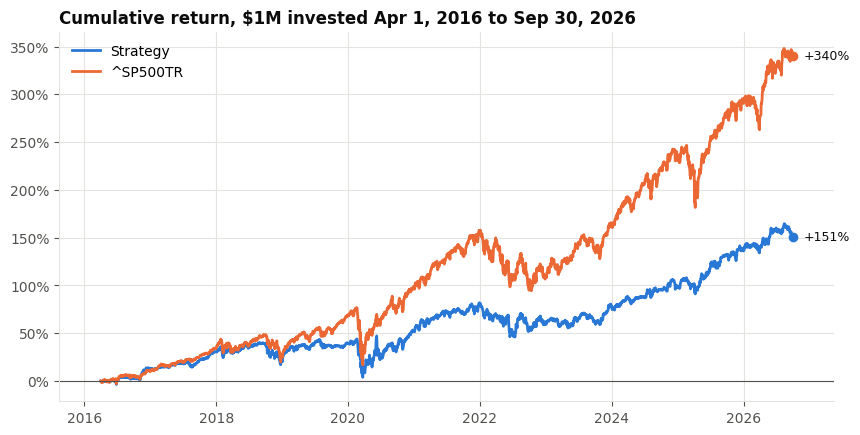

In [9]:
strat_ret, bench_ret = history.nav / 1e6 - 1, bench / 1e6 - 1
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(strat_ret, color=STRAT, lw=2, label="Strategy")
ax.plot(bench_ret, color=BENCH, lw=2, label="^SP500TR")
end_label(ax, strat_ret, f"{strat_ret.iloc[-1]:+.0%}", STRAT)
end_label(ax, bench_ret, f"{bench_ret.iloc[-1]:+.0%}", BENCH)
ax.axhline(0, color=INK2, lw=0.8)
ax.yaxis.set_major_formatter(pct)
ax.margins(x=0.06)
ax.set_title("Cumulative return, $1M invested Apr 1, 2016 to Sep 30, 2026", loc="left")
ax.legend(loc="upper left", frameon=False)
fig.savefig("results/cumulative_returns.png", dpi=150, bbox_inches="tight")
plt.show()


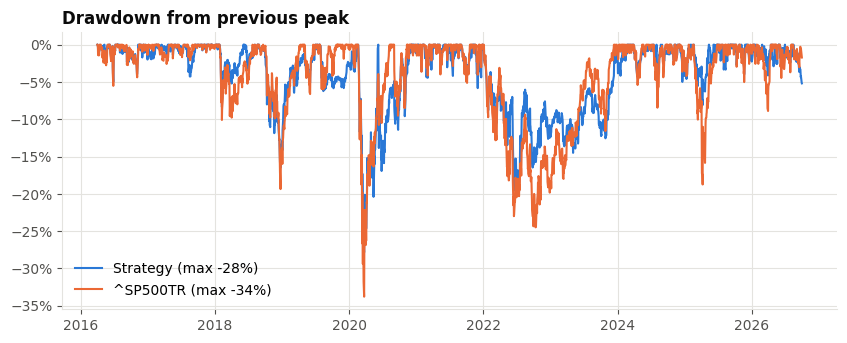

In [10]:
def drawdown(nav):
    return nav / nav.cummax() - 1

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(drawdown(history.nav), color=STRAT, lw=1.5, label=f"Strategy (max {drawdown(history.nav).min():.0%})")
ax.plot(drawdown(bench), color=BENCH, lw=1.5, label=f"^SP500TR (max {drawdown(bench).min():.0%})")
ax.yaxis.set_major_formatter(pct)
ax.set_title("Drawdown from previous peak", loc="left")
ax.legend(loc="lower left", frameon=False)
fig.savefig("results/drawdown.png", dpi=150, bbox_inches="tight")
plt.show()


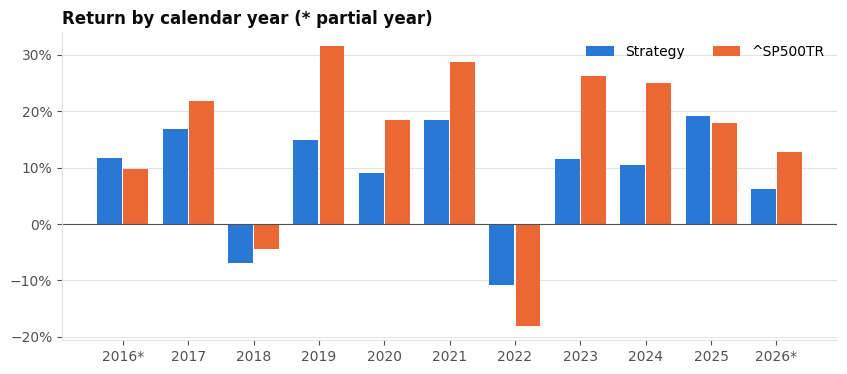

In [11]:
navs = pd.DataFrame({"Strategy": history.nav, "^SP500TR": bench})
year_end = navs.groupby(navs.index.year).last()
start_row = navs.iloc[[0]].set_axis([navs.index.year[0] - 1])          # starting value as "year 2015"
yearly = pd.concat([start_row, year_end]).pct_change().dropna()         # year-end to year-end

fig, ax = plt.subplots(figsize=(10, 4))
x, w = np.arange(len(yearly)), 0.38
ax.bar(x - w / 2 - 0.01, yearly["Strategy"], w, color=STRAT, label="Strategy")
ax.bar(x + w / 2 + 0.01, yearly["^SP500TR"], w, color=BENCH, label="^SP500TR")
ax.set_xticks(x, [f"{y}*" if y in (2016, 2026) else f"{y}" for y in yearly.index])
ax.axhline(0, color=INK2, lw=0.8)
ax.yaxis.set_major_formatter(pct)
ax.grid(axis="x", visible=False)
ax.set_title("Return by calendar year (* partial year)", loc="left")
ax.legend(loc="upper right", frameon=False, ncol=2)
fig.savefig("results/yearly_returns.png", dpi=150, bbox_inches="tight")
plt.show()


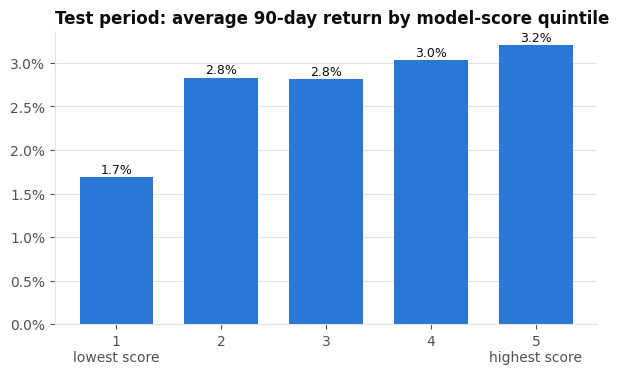

In [12]:
t = test.loc[test.target.notna()].copy()     # evaluation only: outcomes are used after the fact
t["quintile"] = t.groupby("date").score.rank(pct=True).mul(5).apply(np.ceil).astype(int)
t["target_c"] = t.target.clip(*t.target.quantile([.01, .99]))
q = t.groupby(["date", "quintile"]).target_c.mean().unstack().mean()

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(q.index, q.values, color=STRAT, width=0.7)
for i, v in q.items():
    ax.annotate(f"{v:.1%}", (i, v), xytext=(0, 3), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_xticks(q.index, ["1\nlowest score", "2", "3", "4", "5\nhighest score"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.grid(axis="x", visible=False)
ax.set_title("Test period: average 90-day return by model-score quintile", loc="left")
fig.savefig("results/score_quintiles.png", dpi=150, bbox_inches="tight")
plt.show()


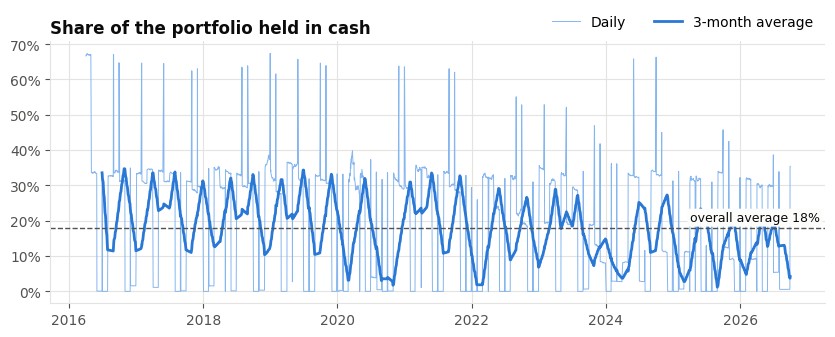

In [13]:
cash_w = history.cash / history.nav
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(cash_w, color="#86b6ef", lw=0.7, label="Daily")
ax.plot(cash_w.rolling(63).mean(), color=STRAT, lw=2, label="3-month average")
ax.axhline(cash_w.mean(), color=INK2, lw=1, ls="--")
ax.annotate(f"overall average {cash_w.mean():.0%}", (1, cash_w.mean()), xycoords=("axes fraction", "data"),
            xytext=(-4, 5), textcoords="offset points", ha="right", color=INK, fontsize=9,
            bbox=dict(boxstyle="round,pad=0.2", fc="#fcfcfb", ec="none"))
ax.yaxis.set_major_formatter(pct)
ax.set_title("Share of the portfolio held in cash", loc="left")
ax.legend(loc="upper right", frameon=False, ncol=2, bbox_to_anchor=(1, 1.15))
fig.savefig("results/cash_weight.png", dpi=150, bbox_inches="tight")
plt.show()


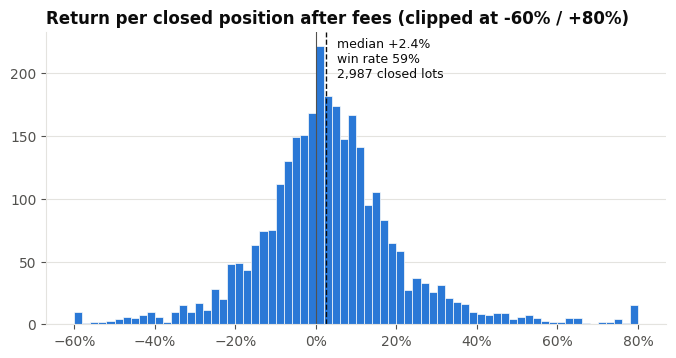

In [14]:
paid = fills.loc[fills.side == "buy", ["lot_id", "cash_change"]].rename(columns={"cash_change": "paid"})
sells = fills.loc[fills.side == "sell"].merge(paid, on="lot_id")
lot_ret = sells.pnl / -sells.paid                     # paid is negative cash, so flip the sign

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(lot_ret.clip(-0.6, 0.8), bins=70, color=STRAT, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(0, color=INK2, lw=0.8)
ax.axvline(lot_ret.median(), color=INK, lw=1, ls="--")
ax.annotate(f"median {lot_ret.median():+.1%}\nwin rate {(lot_ret > 0).mean():.0%}\n{len(lot_ret):,} closed lots",
            (lot_ret.median(), 1), xycoords=("data", "axes fraction"), xytext=(8, -4),
            textcoords="offset points", va="top", color=INK, fontsize=9)
ax.xaxis.set_major_formatter(pct)
ax.grid(axis="x", visible=False)
ax.set_title("Return per closed position after fees (clipped at -60% / +80%)", loc="left")
fig.savefig("results/lot_returns.png", dpi=150, bbox_inches="tight")
plt.show()
